# Unidad IV — K-Means y PCA

David Rafael Aguilar Solis · 22300607 · 10IDGS-G1

Análisis descriptivo reproducible sobre datos procesados validados. `NObeyesdad` se excluye del ajuste; sólo se cruza después para perfilar clusters. Se conservan observaciones duplicadas.

## 1. Contrato y variables
Se verifican huellas, dimensiones y equivalencia raw/procesado. K-Means usa Age, Height, Weight, FCVC, NCP, CH2O, FAF y TUE, estandarizadas con StandardScaler. Son variables numéricas de edad, medidas físicas, alimentación y actividad/uso. La etiqueta no participa en el escalado, PCA ni clustering.

In [1]:
from src.unit_iv import analyze
result=analyze()
print('Entrada:',result['frame'].shape,'duplicados=',int(result['frame'].duplicated().sum()))
print('Variables:',result['features'])
print('k elegido por mayor Silhouette en k=2..9:',result['best_k'])
display(result['scores'])

Entrada: (2111, 17) duplicados= 24
Variables: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
k elegido por mayor Silhouette en k=2..9: 9


,k,inertia,silhouette
0,2,14367.973962,0.145329
1,3,12746.369840,0.149869
2,4,11451.505258,0.160157
3,5,10534.862798,0.169117
4,6,9764.288236,0.166669
5,7,9210.411215,0.166249
6,8,8736.342351,0.167878
7,9,8391.429242,0.172636


## 2. Elección de k
Se comparan inercia y Silhouette para k=2..9. La regla mecánica selecciona el mayor Silhouette y el codo sirve como diagnóstico complementario. El score no es alto por sí mismo ni demuestra que existan clases naturales; la decisión necesita juicio sustantivo.

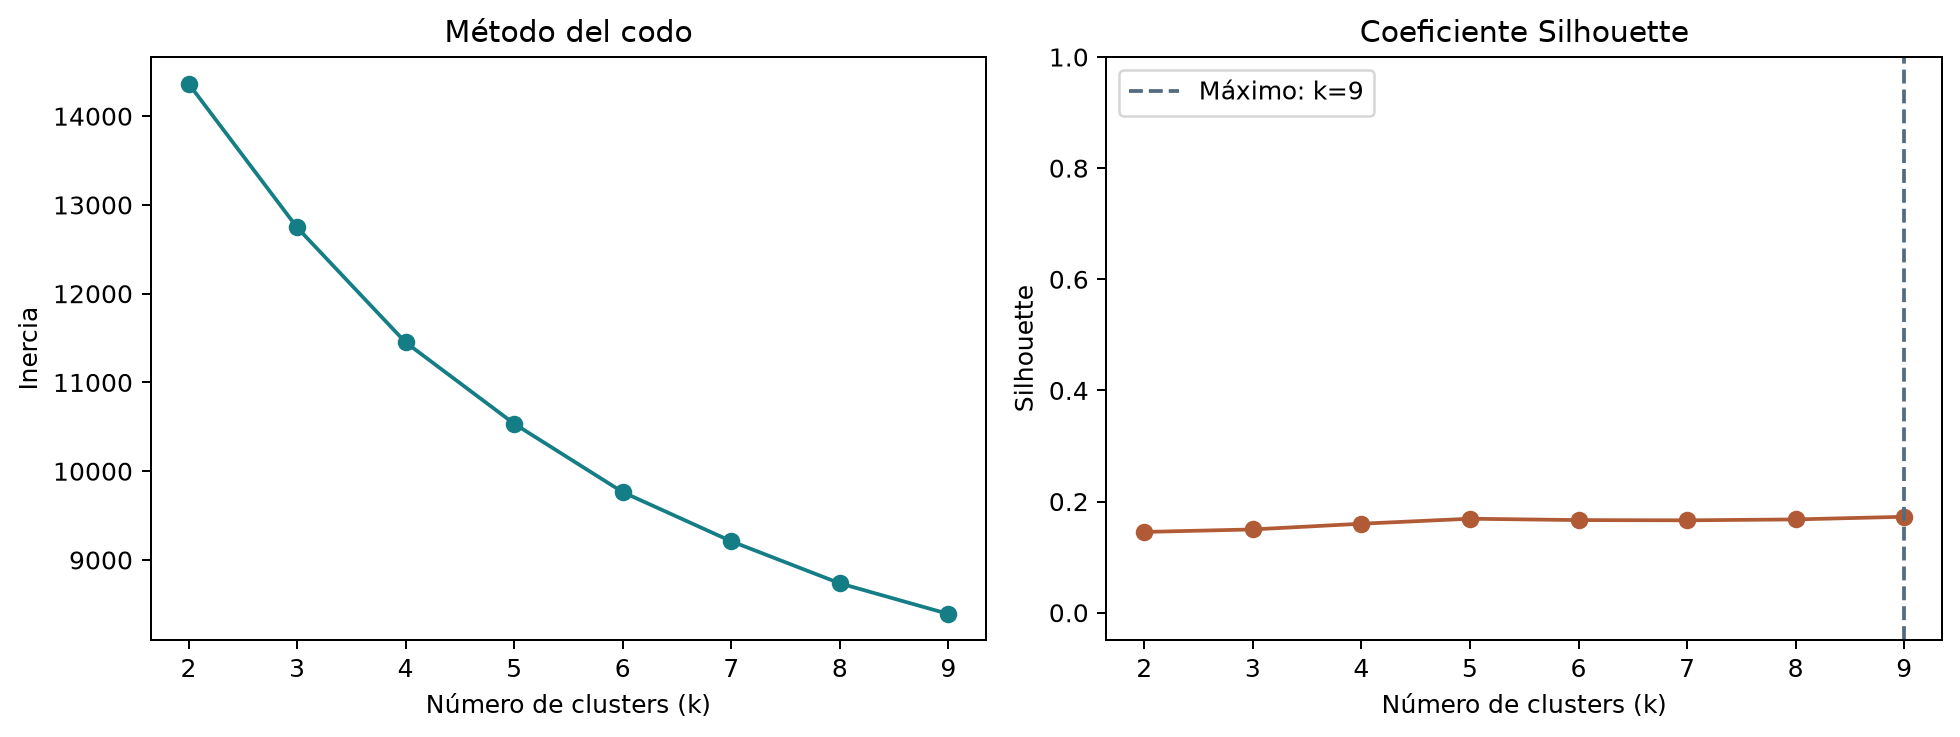

In [2]:
from IPython.display import display, Image
from pathlib import Path
fig=Path('docs/unidad_iv/figuras')
display(Image(filename=str(fig/'seleccion_k.png')))

## 3. PCA
PCA se ajusta a las ocho variables estandarizadas y se usa para reducir a dos dimensiones para visualización. La proporción explicada se reporta explícitamente; la proyección pierde información.

,explained_variance_ratio
PC1,0.226486
PC2,0.186579


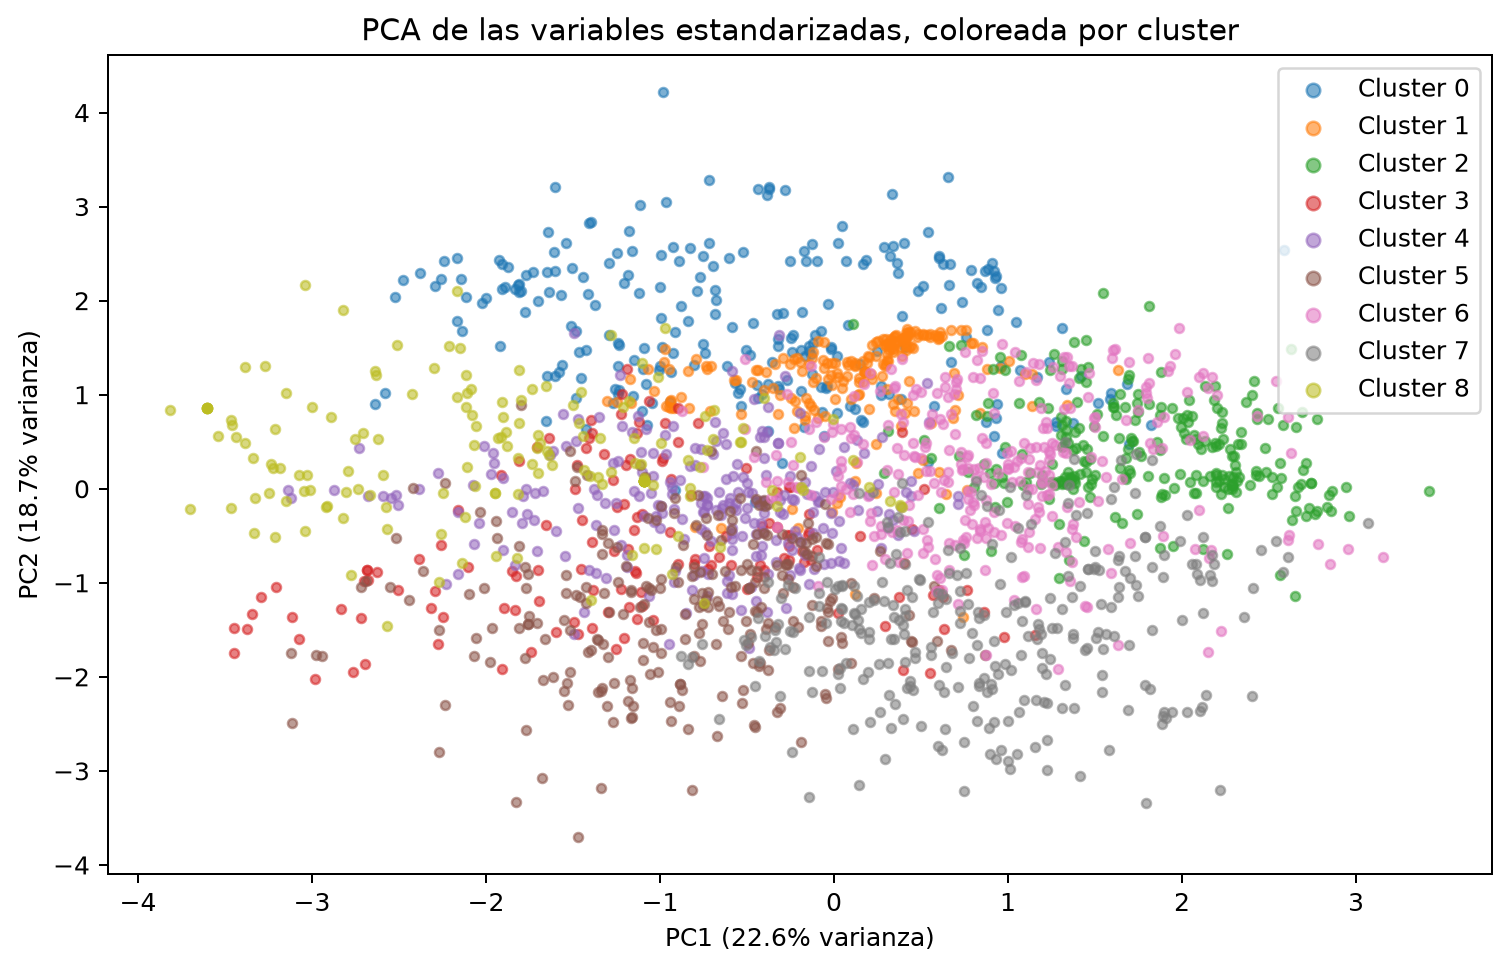

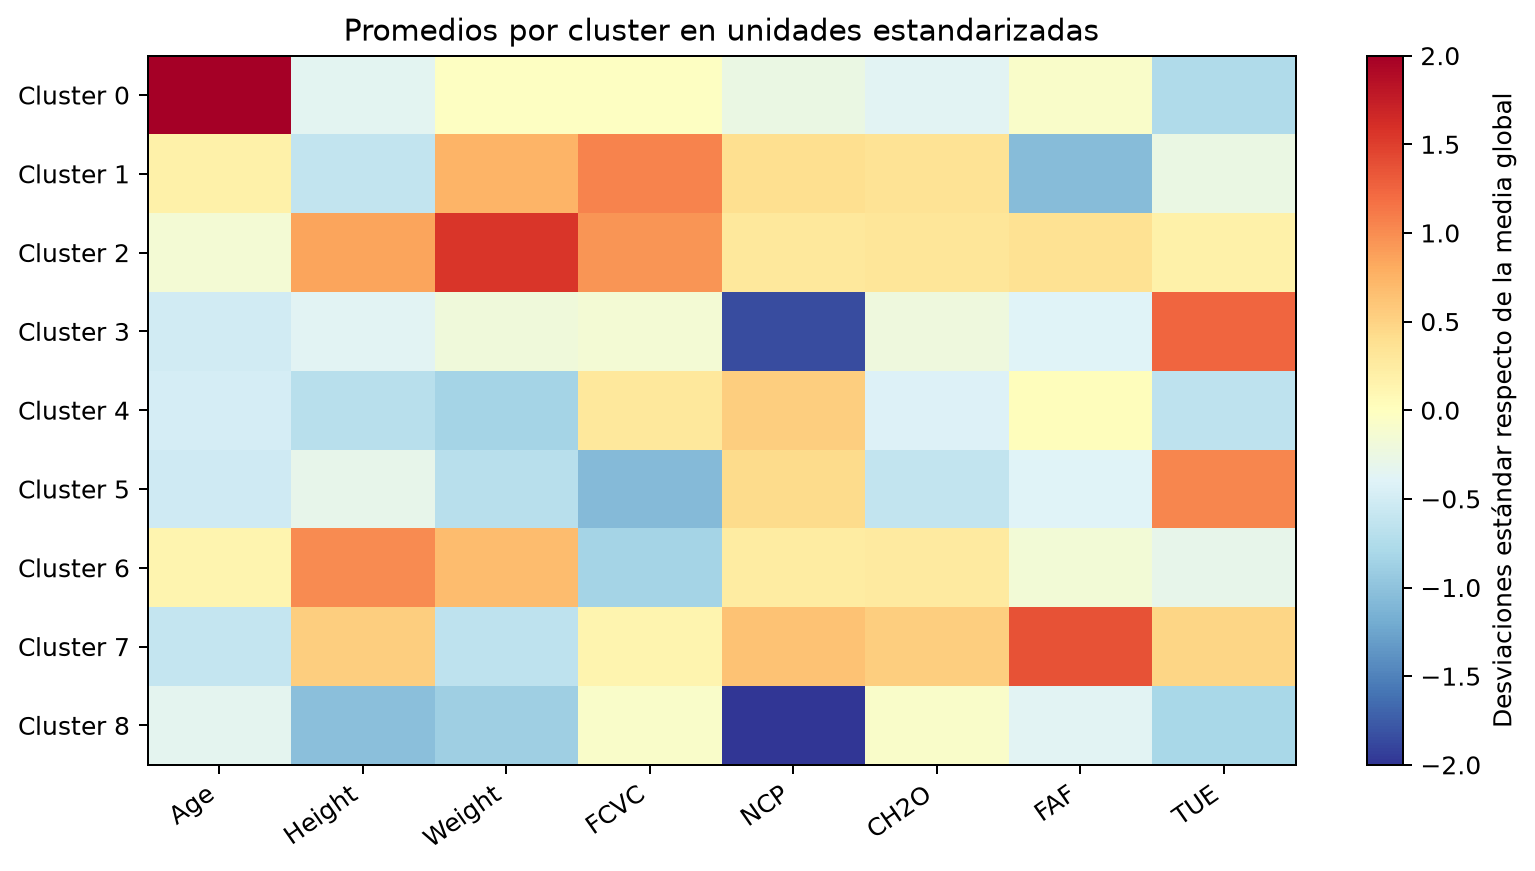

In [3]:
display(result['pca_variance'])
display(Image(filename=str(fig/'pca_clusters.png')))
display(Image(filename=str(fig/'perfil_clusters.png')))

## 4. Perfiles e interpretación
La etiqueta se consulta sólo después del ajuste para describir la composición observada. Las medias de variables originales ayudan a interpretar clusters; no constituyen asociaciones causales ni diagnósticos clínicos.

In [4]:
display(result['numeric_profile'])
display(result['label_profile'])
print('Tamaños:',result['cluster_sizes'])
print('Asignaciones derivadas:',result['assignment_path'])
print('Evidencia:',result['evidence_path'])

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
cluster,,,,,,,,
0,37.5699,1.6695,85.8324,2.4046,2.4844,1.7831,0.9494,0.1997
1,25.4827,1.6442,106.1028,2.9791,2.9948,2.2243,0.1107,0.5010
2,23.4045,1.7809,127.4603,2.9223,2.9110,2.2087,1.3288,0.7714
3,21.0522,1.6678,81.5189,2.3416,1.2481,1.8754,0.6732,1.4150
4,21.3139,1.6374,64.7210,2.5717,3.1058,1.7512,1.0273,0.2601
5,20.9583,1.6732,68.3919,1.8486,3.0231,1.6256,0.6743,1.2939
6,25.1688,1.7960,104.3394,1.9696,2.8724,2.1699,0.8647,0.4699
7,20.5025,1.7521,69.5439,2.4891,3.1743,2.3360,2.1744,0.9520
8,22.1375,1.6059,63.5576,2.3817,1.1392,1.9634,0.7023,0.1660


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
cluster,,,,,,,
0,0.0081,0.0407,0.3252,0.2114,0.0000,0.1585,0.2561
1,0.0000,0.0291,0.0146,0.0049,0.9029,0.0000,0.0485
2,0.0000,0.0000,0.0949,0.3281,0.5455,0.0158,0.0158
3,0.0496,0.1560,0.2979,0.1844,0.0000,0.1986,0.1135
4,0.2186,0.3077,0.1215,0.0243,0.0000,0.2065,0.1215
5,0.2341,0.2460,0.1548,0.0000,0.0000,0.1468,0.2183
6,0.0000,0.0493,0.2632,0.4178,0.0000,0.1053,0.1645
7,0.3593,0.2339,0.0949,0.0000,0.0000,0.1695,0.1424
8,0.2635,0.1617,0.1497,0.0120,0.0000,0.2934,0.1198


Tamaños: {'0': 246, '1': 206, '2': 253, '3': 141, '4': 247, '5': 252, '6': 304, '7': 295, '8': 167}
Asignaciones derivadas: C:\Users\rafle\Documents\REC_ECBD_2026_Aguilar_Solis_David_Rafael\data\processed\unidad_iv_cluster_assignments.csv
Evidencia: C:\Users\rafle\Documents\REC_ECBD_2026_Aguilar_Solis_David_Rafael\docs\unidad_iv\evidencias\verificacion_unidad_iv.json


## 5. Límites
Se conservan 24 filas idénticas, por lo que algunas observaciones tienen peso repetido. La muestra incluye registros sintéticos y no valida generalización a población externa. Age/Height/Weight pueden dominar la geometría aun estandarizados. La asignación por k máximo Silhouette debe considerarse una decisión exploratoria y revisable. La aceptación académica y la entrega no están verificadas por esta ejecución.